# Лабораторна робота: нейронні мережі в PyTorch

**Мета:** побудувати нейромережі для табличних даних, зображень і текстів та порівняти результати.

1. **MLP:** `telesurgery_cybersecurity_dataset.csv`, ціль `Threat Detected` — порівняння з класичними алгоритмами.
2. **CNN:** **EuroSAT** (10 класів супутникових знімків; не MNIST і не CIFAR-10) — CNN з нуля та pretrained MobileNetV3 Small; вплив розміру train.
3. **Тексти:** **20 Newsgroups** з лабораторної №2 з **локального архіву `20newsbydate.tar.gz`**, три класи: `sci.space`, `rec.sport.hockey`, `talk.politics.guns`.

## 0. Встановлення бібліотек і налаштування

встановлюємо необхідні бібліотеки та налаштовуємо середовище для навчання нейронних мереж. Команда `%pip install` встановлює або оновлює бібліотеки, зокрема PyTorch для створення нейромереж, NumPy і Pandas для обробки даних, Matplotlib для графіків та Scikit-learn для підготовки даних і оцінювання моделей. Далі імпортуємо інструменти для роботи з файлами, текстами, датасетами та алгоритмами машинного навчання. `SEED = 42` фіксує генерацію випадкових чисел, щоб результати експериментів були максимально відтворюваними. Через torch.cuda.`is_available()` перевіряємо наявність доступної NVIDIA GPU: якщо вона є, обчислення виконуватимуться на відеокарті (`cuda`), інакше — на процесорі (`cpu`). NUM_WORKERS = 0 означає, що завантаження даних відбуватиметься без додаткових робочих процесів, PIN_MEMORY оптимізує передачу даних на GPU, а `BATCH_SIZE = 64` визначає, що модель оброблятиме по 64 приклади за один крок навчання. Наприкінці задаємо шлях до датасету `telesurgery_cybersecurity_dataset.csv`, цільову змінну Threat Detected і виводимо версію PyTorch та пристрій, на якому працюватиме модель.

In [ ]:
%pip install -U torch torchvision numpy pandas scikit-learn matplotlib gensim

In [3]:
import copy
import random
import re
import tarfile
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Subset

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == 'cuda'
BATCH_SIZE = 64
DATA_PATH = 'telesurgery_cybersecurity_dataset.csv'
TARGET = 'Threat Detected'

print('PyTorch:', torch.__version__, '| Пристрій:', DEVICE)

PyTorch: 2.15.0+cu132 | Пристрій: cpu


### Спільні функції для навчання, оцінки та графіків

**Train loss** обчислюється на навчальних даних з оновленням ваг; **validation loss** — на відкладеній вибірці без оновлення ваг. Зберігаємо ваги найкращої епохи за validation loss (early stopping). Тестову вибірку використовуємо лише для фінальної оцінки.

In [4]:
def _forward_batch(model, batch):
    """(x, y) для таблиць/зображень або (x, lengths, y) для тексту."""
    if len(batch) == 2:
        x, y = batch
        logits = model(x.to(DEVICE))
    elif len(batch) == 3:
        x, lengths, y = batch
        logits = model(x.to(DEVICE), lengths.cpu())
    else:
        raise ValueError('Невідомий формат batch')
    return logits, y.to(DEVICE)


def one_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)
    total_loss, total_correct, count = 0.0, 0, 0

    with torch.set_grad_enabled(is_train):
        for batch in loader:
            logits, targets = _forward_batch(model, batch)
            loss = criterion(logits, targets)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            n = targets.size(0)
            total_loss += loss.item() * n
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            count += n
    return total_loss / count, total_correct / count


def fit_model(model, train_loader, val_loader, epochs=15, lr=1e-3, patience=5):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_loss, best_epoch, stale = float('inf'), 0, 0
    best_weights = copy.deepcopy(model.state_dict())
    t0 = time.perf_counter()

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = one_epoch(model, val_loader, criterion)
        for k, value in [('train_loss', train_loss), ('val_loss', val_loss),
                         ('train_acc', train_acc), ('val_acc', val_acc)]:
            history[k].append(value)
        print(f'Epoch {epoch:02d}/{epochs}: '
              f'train loss={train_loss:.4f}, val loss={val_loss:.4f}, '
              f'train acc={train_acc:.3f}, val acc={val_acc:.3f}')
        if val_loss < best_loss - 1e-4:
            best_loss, best_epoch, stale = val_loss, epoch, 0
            best_weights = copy.deepcopy(model.state_dict())
        else:
            stale += 1
            if stale >= patience:
                print('Early stopping: validation loss не покращується.')
                break

    model.load_state_dict(best_weights)
    elapsed = time.perf_counter() - t0
    history['best_epoch'] = best_epoch
    history['seconds'] = elapsed
    return model, history


def predict_model(model, loader):
    model.eval()
    ys, preds = [], []
    with torch.no_grad():
        for batch in loader:
            logits, y = _forward_batch(model, batch)
            ys.extend(y.cpu().numpy().tolist())
            preds.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    return np.asarray(ys), np.asarray(preds)


def scores(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0)}


def plot_history(history, title):
    ep = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(ep, history['train_loss'], marker='o', label='Train')
    ax[0].plot(ep, history['val_loss'], marker='o', label='Validation')
    ax[0].set(xlabel='Epoch', ylabel='Cross-entropy loss', title=title + ': Loss')
    ax[0].legend(); ax[0].grid(alpha=0.25)
    ax[1].plot(ep, history['train_acc'], marker='o', label='Train')
    ax[1].plot(ep, history['val_acc'], marker='o', label='Validation')
    ax[1].set(xlabel='Epoch', ylabel='Accuracy', title=title + ': Accuracy')
    ax[1].legend(); ax[1].grid(alpha=0.25)
    plt.tight_layout(); plt.show()


def show_report(y_true, y_pred, names, title):
    print(title, scores(y_true, y_pred))
    print(classification_report(y_true, y_pred, labels=np.arange(len(names)),
                                target_names=list(names), zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=np.arange(len(names)), display_labels=list(names),
        xticks_rotation=45, cmap='Blues', colorbar=False
    )
    plt.title(title); plt.tight_layout(); plt.show()

---

## 1. Повнозв'язана нейронна мережа (MLP) — Telesurgery Cybersecurity

**Вхід:** ознаки телехірургічної кібербезпеки. **Ціль:** `Threat Detected`. Відкидаємо три колонки, які були виключені під час попередньої роботи (`Gesture Coordinates`, `Timestamp`, `Encryption Algorithm Used`), якщо вони є в CSV. Числові ознаки заповнюємо медіаною та масштабуємо; категоріальні — one-hot encoding. `ColumnTransformer` навчаємо **лише на train**, щоб уникнути витоку даних.

In [5]:
if not Path(DATA_PATH).is_file():
    raise FileNotFoundError(
        f'Файл {DATA_PATH!r} не знайдено. Поклади CSV поруч із notebook '
        'або зміни змінну DATA_PATH на свій шлях.'
    )

df = pd.read_csv(DATA_PATH)
if TARGET not in df.columns:
    raise KeyError(f'Немає цільової колонки {TARGET!r}. Є: {df.columns.tolist()}')

df = df.dropna(subset=[TARGET]).reset_index(drop=True)
DROP_COLS = ['Gesture Coordinates', 'Timestamp', 'Encryption Algorithm Used']
removed_cols = [c for c in DROP_COLS if c in df.columns]
X = df.drop(columns=[TARGET] + removed_cols)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df[TARGET].astype(str))
tab_classes = label_encoder.classes_.astype(str).tolist()

print('Розмір:', df.shape, '| Ознак без виключених:', X.shape[1])
print('Класи:', dict(zip(tab_classes, np.bincount(y))))
print('Виключені колонки:', removed_cols)
display(df.head())

all_idx = np.arange(len(y))
train_val_idx, test_idx = train_test_split(
    all_idx, test_size=0.15, random_state=SEED, stratify=y
)
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.15 / 0.85, random_state=SEED,
    stratify=y[train_val_idx]
)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
category_features = [c for c in X.columns if c not in numeric_features]
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:  # Для старих версій scikit-learn.
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocess = ColumnTransformer(transformers=[
    ('num', Pipeline([('fill', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), numeric_features),
    ('cat', Pipeline([('fill', SimpleImputer(strategy='most_frequent')),
                      ('onehot', encoder)]), category_features)
], remainder='drop')

X_train = np.asarray(preprocess.fit_transform(X.iloc[train_idx]), dtype=np.float32)
X_val = np.asarray(preprocess.transform(X.iloc[val_idx]), dtype=np.float32)
X_test = np.asarray(preprocess.transform(X.iloc[test_idx]), dtype=np.float32)
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)
print('Кількість класів:', len(tab_classes))

Розмір: (1000, 18) | Ознак без виключених: 15
Класи: {'0': np.int64(283), '1': np.int64(717)}
Виключені колонки: ['Timestamp', 'Encryption Algorithm Used']


,Robot Gesture ID,Gesture Type,"Gesture Coordinates (x, y, z)",Timestamp,Gesture Duration (sec),Robot Status,Message ID,Sender,Receiver,Encryption Algorithm Used,Encryption Status,Network Latency (ms),Data Transfer Rate (Mbps),Threat Type,Threat Severity,Response Time (sec),Response Action Taken,Threat Detected
0,10,Incision,"(1.48, 1.4, 0.02)",2025-02-14 16:32:27,4.37,Idle,22614,Operator,Robot,Two Fish,Encrypted,11,97,Man-in-the-Middle Attack,Low,4.63,Reset Encryption,1
1,8,Diagnosis,"(1.62, 1.81, 0.68)",2025-02-14 16:32:27,3.08,Idle,61556,Operator,Robot,Two Fish,Encrypted,9,88,DoS Attack,Low,3.94,Reset Encryption,1
2,9,Incision,"(0.67, 1.53, 0.06)",2025-02-14 16:32:27,1.11,Active,27848,Operator,Robot,Two Fish,Encrypted,7,26,No Threat,Low,0.00,NaN,0
3,1,Incision,"(1.63, 1.74, 1.92)",2025-02-14 16:32:27,2.72,Idle,60592,Operator,Robot,Two Fish,Encrypted,13,56,Data Breach,High,4.58,Reconnect Connection,1
4,4,Suturing,"(0.53, 0.87, 1.17)",2025-02-14 16:32:27,1.20,Idle,46712,Robot,Operator,Two Fish,Failed,5,41,Man-in-the-Middle Attack,Low,2.46,Isolate Data,1


Train: (700, 729) Validation: (150, 729) Test: (150, 729)
Кількість класів: 2


### 1.1. Класичні моделі для чесного порівняння

Порівнюємо з **Logistic Regression** (як у роботі з PCA), а також із **Random Forest** і **SVM**. Усі отримують той самий train/test split та ті самі ознаки; тест не використовується для добору параметрів.

In [6]:
baselines = {
    'Logistic Regression': LogisticRegression(max_iter=3000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=SEED,
                                            n_jobs=-1),
    'SVM (RBF)': SVC(C=1.0, gamma='scale'),
}
tab_results = []
for name, clf in baselines.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    tab_results.append({'model': name, **scores(y_test, pred)})
print(pd.DataFrame(tab_results).to_string(index=False))

              model  accuracy  f1_macro
Logistic Regression       1.0       1.0
      Random Forest       1.0       1.0
          SVM (RBF)       1.0       1.0


### 1.2. MLP у PyTorch

Архітектура: `вхід → Linear(128) → ReLU → Dropout → Linear(64) → ReLU → Dropout → класи`. Навчаємо з `CrossEntropyLoss` та оптимізатором `Adam`. `Dropout` частково захищає від перенавчання.

Epoch 01/30: train loss=0.6303, val loss=0.5785, train acc=0.717, val acc=0.713
Epoch 02/30: train loss=0.5022, val loss=0.3907, train acc=0.720, val acc=0.727
Epoch 03/30: train loss=0.2866, val loss=0.1665, train acc=0.901, val acc=1.000
Epoch 04/30: train loss=0.1102, val loss=0.0502, train acc=1.000, val acc=1.000
Epoch 05/30: train loss=0.0318, val loss=0.0143, train acc=1.000, val acc=1.000
Epoch 06/30: train loss=0.0105, val loss=0.0055, train acc=1.000, val acc=1.000
Epoch 07/30: train loss=0.0046, val loss=0.0030, train acc=1.000, val acc=1.000
Epoch 08/30: train loss=0.0030, val loss=0.0021, train acc=1.000, val acc=1.000
Epoch 09/30: train loss=0.0021, val loss=0.0016, train acc=1.000, val acc=1.000
Epoch 10/30: train loss=0.0016, val loss=0.0012, train acc=1.000, val acc=1.000
Epoch 11/30: train loss=0.0014, val loss=0.0010, train acc=1.000, val acc=1.000
Epoch 12/30: train loss=0.0010, val loss=0.0009, train acc=1.000, val acc=1.000
Epoch 13/30: train loss=0.0010, val loss

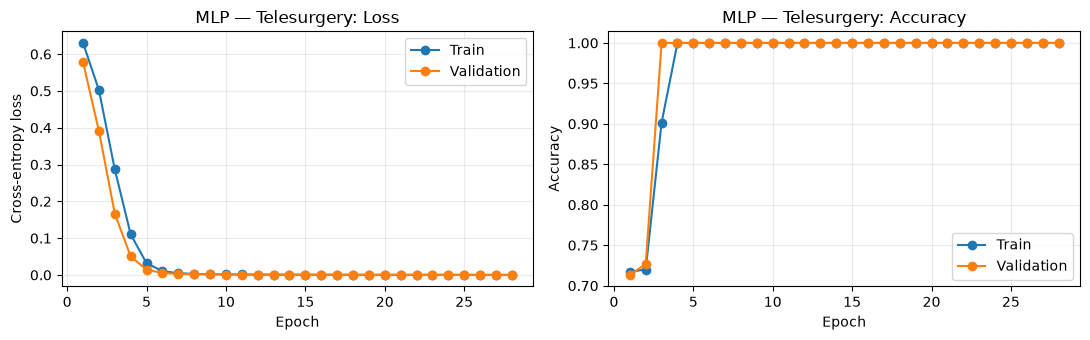

MLP: тестова вибірка {'accuracy': 1.0, 'f1_macro': 1.0}
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        42
           1       1.00      1.00      1.00       108

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150



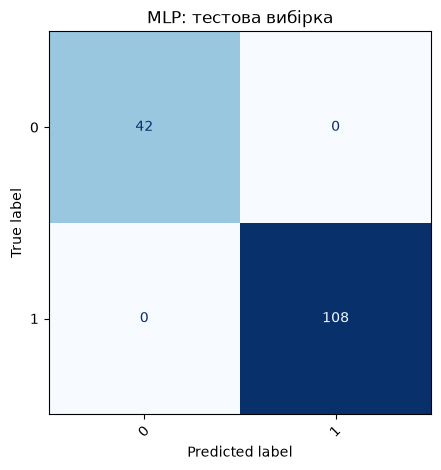

,model,accuracy,f1_macro
0,Logistic Regression,1.0,1.0
1,Random Forest,1.0,1.0
2,SVM (RBF),1.0,1.0
3,PyTorch MLP,1.0,1.0


In [7]:
train_tab = DataLoader(TensorDataset(torch.from_numpy(X_train),
                                    torch.tensor(y_train, dtype=torch.long)),
                       batch_size=BATCH_SIZE, shuffle=True)
val_tab = DataLoader(TensorDataset(torch.from_numpy(X_val),
                                  torch.tensor(y_val, dtype=torch.long)),
                     batch_size=BATCH_SIZE)
test_tab = DataLoader(TensorDataset(torch.from_numpy(X_test),
                                   torch.tensor(y_test, dtype=torch.long)),
                      batch_size=BATCH_SIZE)

class TabularMLP(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        return self.net(x)

mlp = TabularMLP(X_train.shape[1], len(tab_classes))
mlp, mlp_history = fit_model(mlp, train_tab, val_tab,
                             epochs=30, lr=1e-3, patience=6)
plot_history(mlp_history, 'MLP — Telesurgery')
tab_true, tab_pred = predict_model(mlp, test_tab)
show_report(tab_true, tab_pred, tab_classes, 'MLP: тестова вибірка')

tab_results.append({'model': 'PyTorch MLP', **scores(tab_true, tab_pred)})
tab_comparison = pd.DataFrame(tab_results).sort_values('f1_macro', ascending=False)
display(tab_comparison.round(4))

In [8]:
train_last, val_last = mlp_history['train_loss'][-1], mlp_history['val_loss'][-1]
print('Найкраща епоха:', mlp_history['best_epoch'])
if val_last > train_last * 1.2 and val_last > min(mlp_history['val_loss']) * 1.05:
    print('Ознаки перенавчання: train loss нижчий, а validation loss погіршується.')
else:
    print('Вираженого перенавчання за цими простими критеріями не видно.')
if max(x['accuracy'] for x in tab_results) >= 0.999:
    print('УВАГА: майже ідеальна класифікація — перевірте, чи немає ознак, '
          'які безпосередньо або опосередковано розкривають Threat Detected.')
print('Можливо пов’язані з ціллю колонки:',
      [c for c in X.columns if any(t in c.lower() for t in
       ['threat', 'alert', 'attack', 'anomaly', 'intrusion'])])

Найкраща епоха: 22
Вираженого перенавчання за цими простими критеріями не видно.
УВАГА: майже ідеальна класифікація — перевірте, чи немає ознак, які безпосередньо або опосередковано розкривають Threat Detected.
Можливо пов’язані з ціллю колонки: ['Threat Type', 'Threat Severity']


**Проміжний висновок:** Необхідно порівнювати насамперед `f1_macro`, бо класи можуть бути незбалансованими. Якщо train loss зменшується, а val loss починає зростати, це свідчить про перенавчання. Якщо всі моделі майже ідеальні, перевірте залежність ознак від цільової змінної — це може бути надто проста задача або витік мітки.

---

## 2. Згорткові мережі: EuroSAT

**EuroSAT:** 27 000 супутникових RGB-зображень, 64×64 пікселі, **10 класів** (AnnualCrop, Forest, HerbaceousVegetation, Highway, Industrial, Pasture, PermanentCrop, Residential, River, SeaLake). Для швидкості за замовчуванням беремо обмежену **стратифіковану підвибірку** (`MAX_IMAGES_PER_CLASS=250`), але можна встановити `None`, щоб використати всі зображення.

Обидві архітектури отримують **ті самі train/validation/test індекси**. Для оцінки впливу обсягу навчання використаємо 25% і 100% train-даних, не змінюючи validation і test.

100%|██████████| 94.3M/94.3M [00:02<00:00, 43.4MB/s]


EuroSAT, оригінальна кількість: 27000


,Клас,Зображень
0,AnnualCrop,3000
1,Forest,3000
2,HerbaceousVegetation,3000
3,Highway,2500
4,Industrial,2500
5,Pasture,2000
6,PermanentCrop,2500
7,Residential,3000
8,River,2500
9,SeaLake,3000


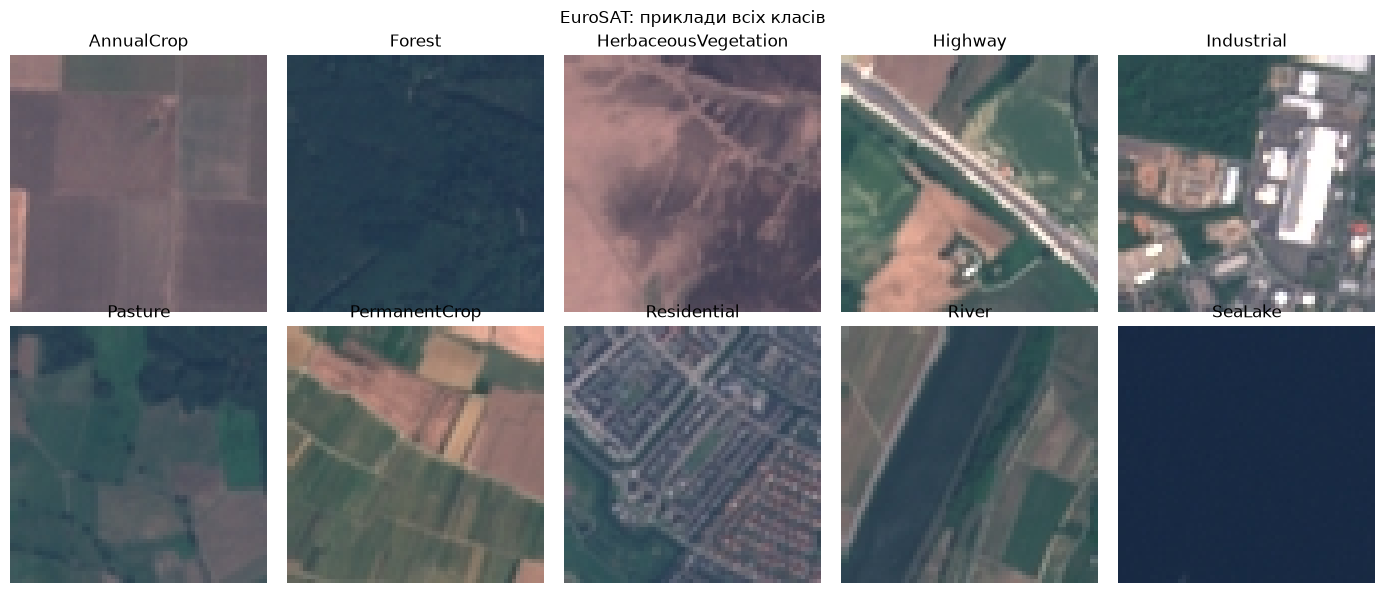

Підвибірка: 2500; train=1750, val=375, test=375


In [9]:
from torchvision import datasets, transforms, models
from torchvision.models import MobileNet_V3_Small_Weights

EUROSAT_ROOT = 'data'
MAX_IMAGES_PER_CLASS = 250
IMAGE_TRAIN_FRACTIONS = [0.25, 1.0]
EPOCHS_SIMPLE_CNN = 6
EPOCHS_MOBILENET = 5

try:
    img_plain = datasets.EuroSAT(root=EUROSAT_ROOT, download=True)
except Exception as exc:
    raise RuntimeError(
        'Не вдалося отримати EuroSAT. Потрібен інтернет для першого '
        'завантаження; можна розпакувати EuroSAT вручну в data/eurosat/2750/.'
    ) from exc

img_class_names = img_plain.classes
img_labels = np.asarray(img_plain.targets)
print('EuroSAT, оригінальна кількість:', len(img_plain))
display(pd.DataFrame({'Клас': img_class_names,
                      'Зображень': np.bincount(img_labels)}))

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for cls, ax in enumerate(axes.ravel()):
    idx = np.flatnonzero(img_labels == cls)[0]
    ax.imshow(img_plain[idx][0]); ax.set_title(img_class_names[cls]); ax.axis('off')
plt.suptitle('EuroSAT: приклади всіх класів')
plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
selected = []
for c in range(len(img_class_names)):
    pool = np.flatnonzero(img_labels == c)
    n = len(pool) if MAX_IMAGES_PER_CLASS is None else min(MAX_IMAGES_PER_CLASS, len(pool))
    selected.extend(rng.choice(pool, size=n, replace=False).tolist())
selected = np.array(selected)

img_train_val_idx, img_test_idx = train_test_split(
    selected, test_size=0.15, random_state=SEED,
    stratify=img_labels[selected]
)
img_train_idx, img_val_idx = train_test_split(
    img_train_val_idx, test_size=0.15 / 0.85, random_state=SEED,
    stratify=img_labels[img_train_val_idx]
)
print(f'Підвибірка: {len(selected)}; train={len(img_train_idx)}, '
      f'val={len(img_val_idx)}, test={len(img_test_idx)}')

### 2.1. Підготовка зображень

**CNN з нуля:** вхід 64×64. **MobileNetV3:** вхід 128×128 з нормалізацією ImageNet. Для train використовуємо повороти-віддзеркалення (у супутникових знімках орієнтація часто не визначає клас). Validation/test — без випадкової аугментації.

In [10]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def image_transform(size, augment=False):
    steps = [transforms.Resize((size, size))]
    if augment:
        steps += [transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip()]
    steps += [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    return transforms.Compose(steps)

image_datasets = {}
for kind, size in [('CNN з нуля', 64), ('Pretrained MobileNetV3', 128)]:
    train_ds = datasets.EuroSAT(root=EUROSAT_ROOT,
                               transform=image_transform(size, augment=True))
    eval_ds = datasets.EuroSAT(root=EUROSAT_ROOT,
                              transform=image_transform(size, augment=False))
    assert train_ds.samples == eval_ds.samples == img_plain.samples
    image_datasets[kind] = (train_ds, eval_ds)

def fraction_indices(base_indices, fraction):
    if fraction == 1.0:
        return np.asarray(base_indices)
    local_rng = np.random.default_rng(SEED + 777)
    out = []
    for cls in np.unique(img_labels[base_indices]):
        candidates = np.asarray(base_indices)[img_labels[base_indices] == cls]
        n = max(1, round(len(candidates) * fraction))
        out.extend(local_rng.choice(candidates, size=n, replace=False).tolist())
    return np.asarray(out)

def make_image_loaders(kind, fraction):
    tr_ds, ev_ds = image_datasets[kind]
    subset = fraction_indices(img_train_idx, fraction)
    loaders = []
    for ds, ids, shuffle in [(tr_ds, subset, True),
                             (ev_ds, img_val_idx, False),
                             (ev_ds, img_test_idx, False)]:
        loaders.append(DataLoader(Subset(ds, ids.tolist()), batch_size=BATCH_SIZE,
                                  shuffle=shuffle, num_workers=NUM_WORKERS,
                                  pin_memory=PIN_MEMORY))
    return loaders, len(subset)

### 2.2. Архітектури

**Проста CNN:** три блоки `Conv2d → BatchNorm → ReLU → MaxPool`, потім `AdaptiveAvgPool`, `Flatten`, `Linear` і вихідний класифікатор.

При **Transfer learning** ми використовуємо ваги MobileNetV3, навчені на ImageNet; замінюємо останній `Linear` на 10 класів. Навчаємо класифікатор і **останні два блоки** згорткової частини; інші ваги заморожені. Це часткове fine-tuning.

In [11]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, n_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def create_mobilenet(n_classes):
    try:
        net = models.mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT)
    except Exception as exc:
        raise RuntimeError(
            'Ваги MobileNetV3 не завантажились. Потрібен інтернет один раз '
            'або вже збережені ваги в кеші torch/hub/checkpoints.'
        ) from exc
    for p in net.features.parameters():
        p.requires_grad = False
    for p in net.features[-2:].parameters():
        p.requires_grad = True
    last = net.classifier[-1]
    net.classifier[-1] = nn.Linear(last.in_features, n_classes)
    return net

print('Параметрів простої CNN:', sum(p.numel() for p in SimpleCNN(10).parameters()))

Параметрів простої CNN: 357258


### 2.3. Навчання й порівняння на 25% та 100% train

На 25% і 100% навчаємо **обидві моделі з нової ініціалізації**. Для порівняння швидкості фіксуємо число епох, номер найкращої епохи та реальний час навчання.

In [12]:
image_runs = {}
image_rows = []

for fraction in IMAGE_TRAIN_FRACTIONS:
    for kind in ['CNN з нуля', 'Pretrained MobileNetV3']:
        print('\n' + '=' * 65)
        print(f'{kind}, частка train={fraction:.0%}')
        train_loader, val_loader, test_loader = make_image_loaders(kind, fraction)[0]
        train_count = len(train_loader.dataset)
        if kind == 'CNN з нуля':
            net = SimpleCNN(len(img_class_names))
            epochs, lr = EPOCHS_SIMPLE_CNN, 1e-3
        else:
            net = create_mobilenet(len(img_class_names))
            epochs, lr = EPOCHS_MOBILENET, 2e-4
        net, hist = fit_model(net, train_loader, val_loader,
                              epochs=epochs, lr=lr, patience=4)
        y_true, y_pred = predict_model(net, test_loader)
        m = scores(y_true, y_pred)
        image_runs[(fraction, kind)] = {'history': hist, 'metrics': m,
                                        'y_true': y_true, 'y_pred': y_pred}
        image_rows.append({'частка_train': f'{fraction:.0%}', 'модель': kind,
                           'train_n': train_count, 'accuracy': m['accuracy'],
                           'f1_macro': m['f1_macro'],
                           'найкраща_епоха': hist['best_epoch'],
                           'час_навчання_с': hist['seconds']})
        print(f'Результат тесту: accuracy={m["accuracy"]:.4f}, '
              f'macro F1={m["f1_macro"]:.4f}; час={hist["seconds"]:.1f} с')
        del net
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()

image_comparison = pd.DataFrame(image_rows)
display(image_comparison.round(4))


CNN з нуля, частка train=25%
Epoch 01/6: train loss=2.0372, val loss=2.1518, train acc=0.282, val acc=0.240
Epoch 02/6: train loss=1.6319, val loss=1.9376, train acc=0.375, val acc=0.307
Epoch 03/6: train loss=1.4480, val loss=1.7689, train acc=0.430, val acc=0.384
Epoch 04/6: train loss=1.2787, val loss=1.5850, train acc=0.532, val acc=0.419
Epoch 05/6: train loss=1.1473, val loss=1.3120, train acc=0.570, val acc=0.504
Epoch 06/6: train loss=1.0964, val loss=1.2106, train acc=0.607, val acc=0.560
Результат тесту: accuracy=0.5227, macro F1=0.5022; час=48.7 с

Pretrained MobileNetV3, частка train=25%
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 85.4MB/s]


Epoch 01/5: train loss=2.2316, val loss=2.1201, train acc=0.191, val acc=0.331
Epoch 02/5: train loss=1.7965, val loss=1.9617, train acc=0.466, val acc=0.464
Epoch 03/5: train loss=1.5010, val loss=1.8143, train acc=0.634, val acc=0.520
Epoch 04/5: train loss=1.2243, val loss=1.6755, train acc=0.725, val acc=0.565
Epoch 05/5: train loss=0.9915, val loss=1.5480, train acc=0.823, val acc=0.600
Результат тесту: accuracy=0.5520, macro F1=0.5354; час=26.8 с

CNN з нуля, частка train=100%
Epoch 01/6: train loss=1.6777, val loss=2.0608, train acc=0.382, val acc=0.312
Epoch 02/6: train loss=1.2553, val loss=0.9749, train acc=0.547, val acc=0.640
Epoch 03/6: train loss=1.1089, val loss=0.9880, train acc=0.602, val acc=0.603
Epoch 04/6: train loss=1.0455, val loss=0.8706, train acc=0.626, val acc=0.680
Epoch 05/6: train loss=0.9818, val loss=0.8363, train acc=0.646, val acc=0.693
Epoch 06/6: train loss=0.8675, val loss=0.7066, train acc=0.685, val acc=0.739
Результат тесту: accuracy=0.7227, macr

,частка_train,модель,train_n,accuracy,f1_macro,найкраща_епоха,час_навчання_с
0,25%,CNN з нуля,440,0.5227,0.5022,6,48.6618
1,25%,Pretrained MobileNetV3,440,0.5520,0.5354,5,26.7955
2,100%,CNN з нуля,1750,0.7227,0.7060,6,163.5253
3,100%,Pretrained MobileNetV3,1750,0.7520,0.7510,5,81.5201


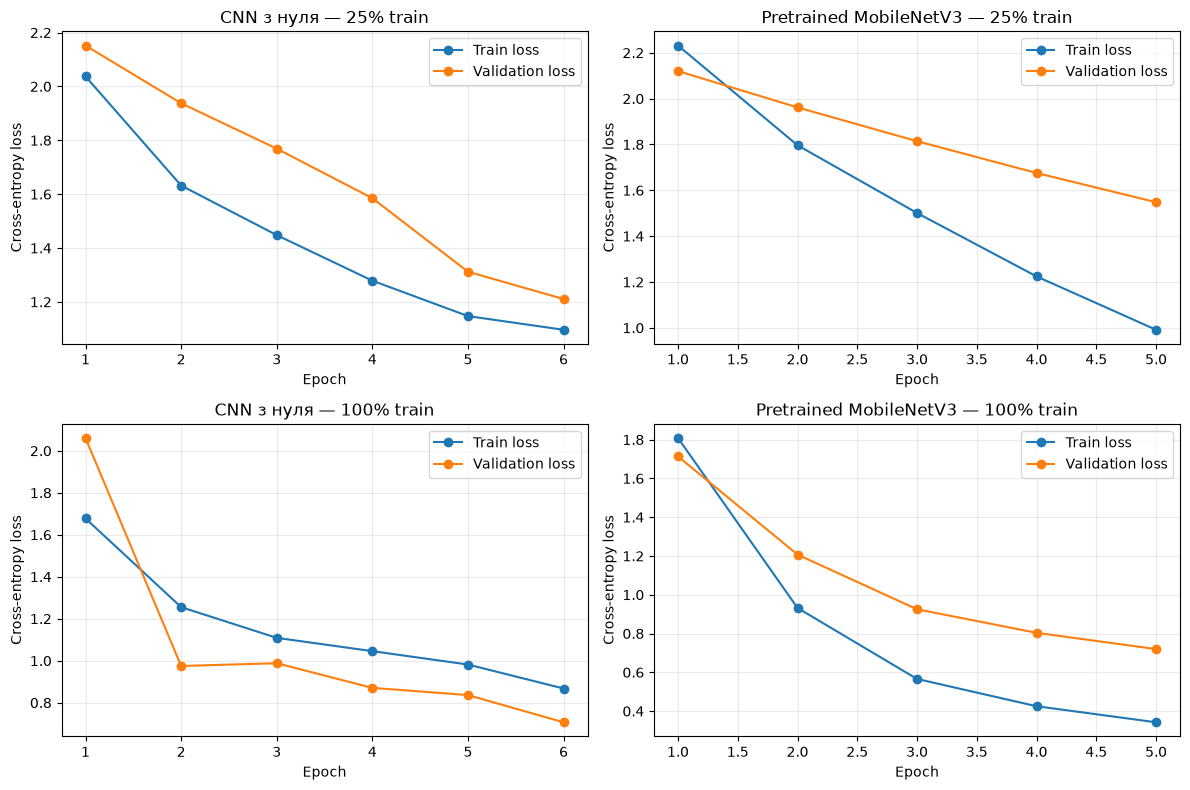

EuroSAT: CNN з нуля, 100% train {'accuracy': 0.7226666666666667, 'f1_macro': 0.7059953861205172}
                      precision    recall  f1-score   support

          AnnualCrop       0.66      0.89      0.76        37
              Forest       0.77      0.92      0.84        37
HerbaceousVegetation       0.88      0.18      0.30        38
             Highway       0.62      0.61      0.61        38
          Industrial       0.88      0.95      0.91        38
             Pasture       0.63      0.97      0.77        37
       PermanentCrop       0.49      0.53      0.51        38
         Residential       0.94      0.81      0.87        37
               River       0.69      0.68      0.68        37
             SeaLake       0.93      0.71      0.81        38

            accuracy                           0.72       375
           macro avg       0.75      0.72      0.71       375
        weighted avg       0.75      0.72      0.70       375



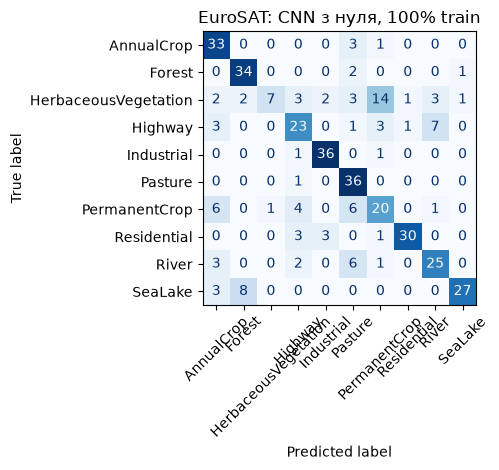

EuroSAT: Pretrained MobileNetV3, 100% train {'accuracy': 0.752, 'f1_macro': 0.7509528203808661}
                      precision    recall  f1-score   support

          AnnualCrop       0.67      0.92      0.77        37
              Forest       0.59      0.95      0.73        37
HerbaceousVegetation       0.65      0.74      0.69        38
             Highway       0.95      0.53      0.68        38
          Industrial       0.96      0.63      0.76        38
             Pasture       0.82      0.62      0.71        37
       PermanentCrop       0.75      0.79      0.77        38
         Residential       0.71      0.73      0.72        37
               River       0.79      0.73      0.76        37
             SeaLake       0.94      0.89      0.92        38

            accuracy                           0.75       375
           macro avg       0.78      0.75      0.75       375
        weighted avg       0.79      0.75      0.75       375



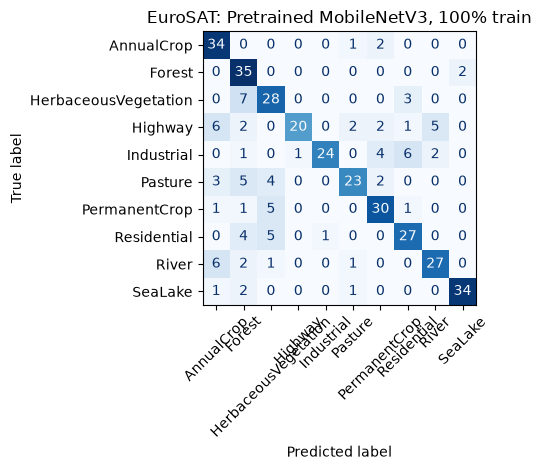

In [13]:
fig, axes = plt.subplots(len(IMAGE_TRAIN_FRACTIONS), 2,
                         figsize=(12, 4 * len(IMAGE_TRAIN_FRACTIONS)), squeeze=False)
for i, fraction in enumerate(IMAGE_TRAIN_FRACTIONS):
    for j, kind in enumerate(['CNN з нуля', 'Pretrained MobileNetV3']):
        hist = image_runs[(fraction, kind)]['history']
        ep = range(1, len(hist['val_loss']) + 1)
        ax = axes[i, j]
        ax.plot(ep, hist['train_loss'], marker='o', label='Train loss')
        ax.plot(ep, hist['val_loss'], marker='o', label='Validation loss')
        ax.set(title=f'{kind} — {fraction:.0%} train', xlabel='Epoch',
               ylabel='Cross-entropy loss')
        ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

for kind in ['CNN з нуля', 'Pretrained MobileNetV3']:
    result = image_runs[(1.0, kind)]
    show_report(result['y_true'], result['y_pred'], img_class_names,
                f'EuroSAT: {kind}, 100% train')

---

## 3. Нейронні мережі для класифікації текстів — датасет з Lab 2

Використовуємо `20newsbydate.tar.gz`:

- `categories = ["sci.space", "rec.sport.hockey", "talk.politics.guns"]`;
- відкриваємо архів через `tarfile.open(..., "r:gz")`, читаємо файли в `latin-1`;
- видаляємо заголовки (`strip_newsgroup_header`), футери (`strip_newsgroup_footer`) і цитати (`strip_newsgroup_quoting`) засобами scikit-learn, **як у Lab 2**;
- `class_names = sorted(categories)`, мітка — індекс відповідної категорії; перемішуємо з `np.random.RandomState(SEED)`.

Після цього: stratified train/validation/test → токенізація → словник **лише за train** → індексація → padding/truncation → BiGRU. Так уникаємо витоку тестових даних через словник чи preprocessing.

In [17]:
from sklearn.datasets._twenty_newsgroups import (
    strip_newsgroup_header,
    strip_newsgroup_footer,
    strip_newsgroup_quoting,
)

categories = ["sci.space", "rec.sport.hockey", "talk.politics.guns"]
class_names = sorted(categories)

ARCHIVE_PATH = Path("20newsbydate.tar.gz")
if not ARCHIVE_PATH.is_file():
    # Дозволяємо також зберігати датасет у папці data/.
    alternate_path = Path("data") / ARCHIVE_PATH.name
    if alternate_path.is_file():
        ARCHIVE_PATH = alternate_path
    else:
        raise FileNotFoundError(
            "Не знайдено 20newsbydate.tar.gz. Поклади архів поруч із .ipynb "
            "або в папку data/. Розпаковувати архів не потрібно."
        )

texts, target = [], []

with tarfile.open(ARCHIVE_PATH, "r:gz") as archive:
    for member in archive:
        if not member.isfile():
            continue

        parts = member.name.split("/")
        if len(parts) < 3 or parts[-2] not in categories:
            continue

        f = archive.extractfile(member)
        if f is None:
            continue

        text = f.read().decode("latin-1")
        text = strip_newsgroup_header(text)
        text = strip_newsgroup_footer(text)
        text = strip_newsgroup_quoting(text)

        texts.append(text)
        target.append(class_names.index(parts[-2]))

target = np.array(target, dtype=np.int64)
if len(texts) == 0:
    raise ValueError("В архіві немає документів потрібних трьох категорій.")

rng = np.random.RandomState(SEED)
idx = rng.permutation(len(texts))
texts = [texts[i] for i in idx]
target = target[idx]

text_labels = target
text_classes = class_names
text_source = str(ARCHIVE_PATH)

print("Джерело:", text_source)
print("Документів:", len(texts), "| класи:", class_names)
print(pd.Series(target).map(dict(enumerate(class_names))).value_counts())
print("\nПриклад:\n", texts[0][:400])

Джерело: 20newsbydate.tar.gz
Документів: 2896 | класи: ['rec.sport.hockey', 'sci.space', 'talk.politics.guns']
rec.sport.hockey      999
sci.space             987
talk.politics.guns    910
Name: count, dtype: int64

Приклад:
 


In [19]:
MAX_VOCAB = 20000
MAX_LEN = 200

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

text_indices = np.arange(len(text_labels))
text_train_val_idx, text_test_idx = train_test_split(
    text_indices, test_size=0.15, stratify=text_labels, random_state=SEED)
text_train_idx, text_val_idx = train_test_split(
    text_train_val_idx, test_size=0.15 / 0.85,
    stratify=text_labels[text_train_val_idx], random_state=SEED)

vocab_counter = Counter(word for i in text_train_idx for word in tokenize(texts[i]))
vocab = {'<PAD>': 0, '<UNK>': 1}
for word, _ in vocab_counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)
PAD_ID, UNK_ID = 0, 1


def encode_text(text):
    ids = [vocab.get(word, UNK_ID) for word in tokenize(text)[:MAX_LEN]]
    if not ids:
        ids = [UNK_ID]
    length = len(ids)
    ids = ids + [PAD_ID] * (MAX_LEN - length)
    return ids, length


def make_text_loader(indices, shuffle=False):
    encoded = [encode_text(texts[int(i)]) for i in indices]
    xx = torch.tensor([pair[0] for pair in encoded], dtype=torch.long)
    lengths = torch.tensor([pair[1] for pair in encoded], dtype=torch.long)
    yy = torch.tensor(text_labels[indices], dtype=torch.long)
    return DataLoader(TensorDataset(xx, lengths, yy), batch_size=BATCH_SIZE,
                      shuffle=shuffle, num_workers=NUM_WORKERS)

text_train_loader = make_text_loader(text_train_idx, shuffle=True)
text_val_loader = make_text_loader(text_val_idx)
text_test_loader = make_text_loader(text_test_idx)
print('Словник:', len(vocab), '| Довжина послідовності:', MAX_LEN)
print('Train/Val/Test:', len(text_train_idx), len(text_val_idx), len(text_test_idx))
print('Приклад токенів:', tokenize(texts[0])[:20])

Словник: 20000 | Довжина послідовності: 200
Train/Val/Test: 2026 435 435
Приклад токенів: []


### 3.1. Дві BiGRU з однаковою архітектурою



In [21]:
from torch.nn.utils.rnn import pack_padded_sequence

EMBED_DIM = 50

class TextBiGRU(nn.Module):
    def __init__(self, vocab_size, n_classes, embed_dim=50,
                 hidden_dim=64, pretrained_matrix=None):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        if pretrained_matrix is not None:
            self.embedding.weight.data.copy_(torch.tensor(pretrained_matrix,
                                                          dtype=torch.float32))
        self.gru = nn.GRU(input_size=embed_dim, hidden_size=hidden_dim,
                          batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.30)
        self.fc = nn.Linear(hidden_dim * 2, n_classes)

    def forward(self, x, lengths):
        embedded = self.embedding(x)
        packed = pack_padded_sequence(embedded, lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        _, hidden = self.gru(packed)
        combined = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.fc(self.dropout(combined))


def load_glove_for_vocab(vocab_dict, dim=50, local_path=Path('data/glove.6B.50d.txt')):
    rng = np.random.default_rng(SEED)
    matrix = rng.normal(0, 0.05, (len(vocab_dict), dim)).astype(np.float32)
    matrix[PAD_ID] = 0.0
    hits = 0
    if local_path.is_file():
        print('GloVe: читаємо локальний файл', local_path)
        with local_path.open('r', encoding='utf-8', errors='ignore') as f:
            for line in f:
                pieces = line.rstrip().split(' ')
                if len(pieces) != dim + 1:
                    continue
                word = pieces[0]
                if word in vocab_dict:
                    matrix[vocab_dict[word]] = np.asarray(pieces[1:], dtype=np.float32)
                    hits += 1
    else:
        try:
            import gensim.downloader as api
        except ImportError as exc:
            raise ImportError('Встановіть gensim: %pip install gensim') from exc
        try:
            glove = api.load('glove-wiki-gigaword-50')
        except Exception as exc:
            raise RuntimeError(
                'Не вдалося завантажити GloVe через gensim (потрібен інтернет один раз). '
                'Альтернатива: покладіть glove.6B.50d.txt у папку data/.'
            ) from exc
        for word, idx in vocab_dict.items():
            if word in glove:
                matrix[idx] = glove[word]
                hits += 1
        del glove
    matrix[PAD_ID] = 0.0
    print(f'Вектори знайдено для {hits}/{len(vocab_dict)} токенів '
          f'({100 * hits/len(vocab_dict):.1f}%). OOV ініціалізовані випадково.')
    return matrix

pretrained_embeddings = load_glove_for_vocab(vocab, EMBED_DIM)

[==================================================] 100.0% 66.0/66.0MB downloaded
Вектори знайдено для 16969/20000 токенів (84.8%). OOV ініціалізовані випадково.


In [23]:
TEXT_EPOCHS = 15

text_runs = {}
text_rows = []
for kind, matrix in [('Random Embedding', None), ('Pretrained GloVe', pretrained_embeddings)]:
    print('\n' + '=' * 65 + '\nТекстова модель:', kind)
    torch.manual_seed(SEED)
    net = TextBiGRU(vocab_size=len(vocab), n_classes=len(text_classes),
                    embed_dim=EMBED_DIM, hidden_dim=64,
                    pretrained_matrix=matrix)
    net, hist = fit_model(net, text_train_loader, text_val_loader,
                          epochs=TEXT_EPOCHS, lr=1e-3, patience=3)
    y_true, y_pred = predict_model(net, text_test_loader)
    metric = scores(y_true, y_pred)
    text_runs[kind] = {'history': hist, 'metrics': metric,
                       'y_true': y_true, 'y_pred': y_pred}
    text_rows.append({'модель': kind, **metric,
                      'найкраща_епоха': hist['best_epoch'],
                      'час_навчання_с': hist['seconds'],
                      'std_зміни_val_loss': float(np.std(np.diff(hist['val_loss'])))
                      if len(hist['val_loss']) > 1 else float('nan')})
    print('Тест:', metric)
    del net
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

text_comparison = pd.DataFrame(text_rows)
display(text_comparison.round(4))


Текстова модель: Random Embedding
Epoch 01/15: train loss=1.1038, val loss=1.0865, train acc=0.354, val acc=0.393
Epoch 02/15: train loss=1.0564, val loss=1.0677, train acc=0.451, val acc=0.407
Epoch 03/15: train loss=1.0077, val loss=1.0474, train acc=0.524, val acc=0.432
Epoch 04/15: train loss=0.9251, val loss=0.9855, train acc=0.583, val acc=0.448
Epoch 05/15: train loss=0.7334, val loss=0.8831, train acc=0.677, val acc=0.536
Epoch 06/15: train loss=0.5865, val loss=0.8132, train acc=0.766, val acc=0.586
Epoch 07/15: train loss=0.4520, val loss=0.7673, train acc=0.823, val acc=0.625
Epoch 08/15: train loss=0.3642, val loss=0.7294, train acc=0.856, val acc=0.678
Epoch 09/15: train loss=0.2650, val loss=0.7429, train acc=0.897, val acc=0.674
Epoch 10/15: train loss=0.1995, val loss=0.6789, train acc=0.931, val acc=0.720
Epoch 11/15: train loss=0.1678, val loss=0.6915, train acc=0.942, val acc=0.703
Epoch 12/15: train loss=0.1238, val loss=0.6931, train acc=0.959, val acc=0.749
Epoch

,модель,accuracy,f1_macro,найкраща_епоха,час_навчання_с,std_зміни_val_loss
0,Random Embedding,0.7471,0.7470,10,364.3509,0.0366
1,Pretrained GloVe,0.8851,0.8846,6,232.6647,0.1642


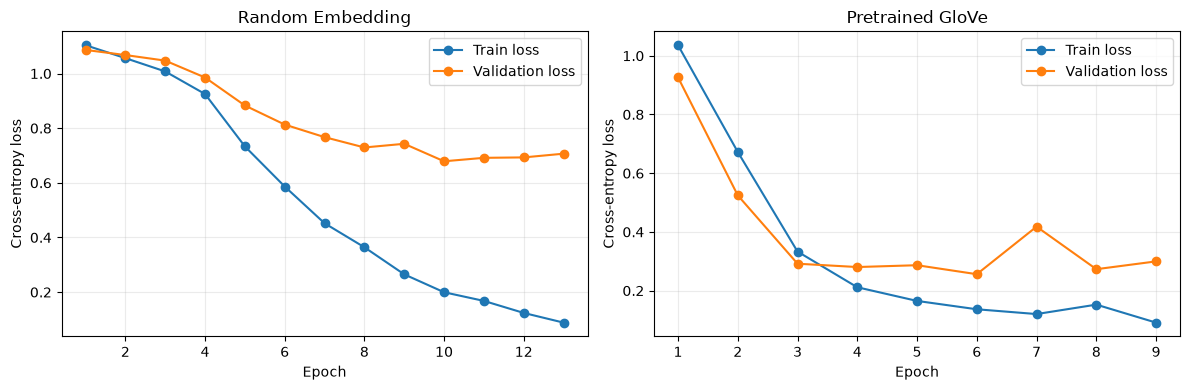

20 Newsgroups: Random Embedding {'accuracy': 0.7471264367816092, 'f1_macro': 0.7470339261640065}
                    precision    recall  f1-score   support

  rec.sport.hockey       0.86      0.81      0.83       150
         sci.space       0.71      0.67      0.69       148
talk.politics.guns       0.67      0.77      0.72       137

          accuracy                           0.75       435
         macro avg       0.75      0.75      0.75       435
      weighted avg       0.75      0.75      0.75       435



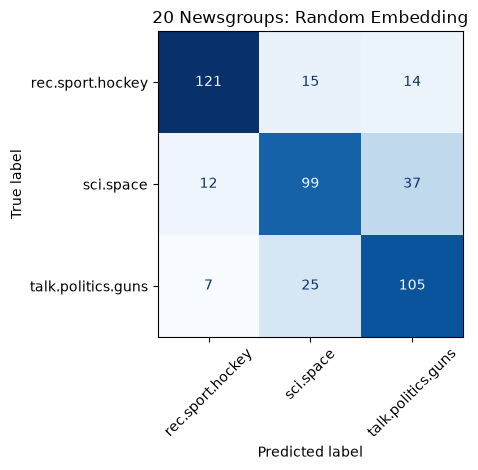

20 Newsgroups: Pretrained GloVe {'accuracy': 0.8850574712643678, 'f1_macro': 0.8846457200454033}
                    precision    recall  f1-score   support

  rec.sport.hockey       0.95      0.92      0.94       150
         sci.space       0.90      0.84      0.87       148
talk.politics.guns       0.81      0.90      0.85       137

          accuracy                           0.89       435
         macro avg       0.89      0.89      0.88       435
      weighted avg       0.89      0.89      0.89       435



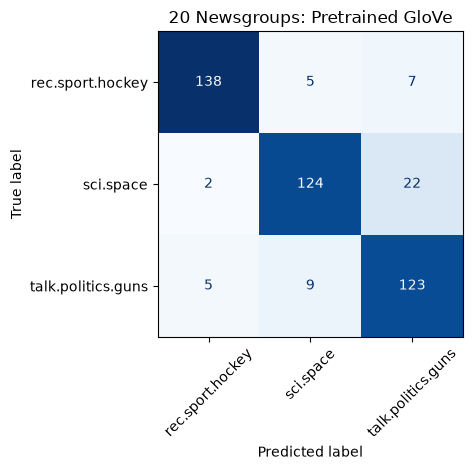

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, kind in zip(axes, ['Random Embedding', 'Pretrained GloVe']):
    h = text_runs[kind]['history']
    epochs = range(1, len(h['val_loss']) + 1)
    ax.plot(epochs, h['train_loss'], 'o-', label='Train loss')
    ax.plot(epochs, h['val_loss'], 'o-', label='Validation loss')
    ax.set(title=kind, xlabel='Epoch', ylabel='Cross-entropy loss')
    ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

for kind in ['Random Embedding', 'Pretrained GloVe']:
    r = text_runs[kind]
    show_report(r['y_true'], r['y_pred'], text_classes, f'20 Newsgroups: {kind}')

---

## 4. Підсумкові результати та автоматичні висновки



In [25]:
print('=== 1. Табличні дані ===')
display(tab_comparison.round(4))
mlp_f1 = next(r['f1_macro'] for r in tab_results if r['model'] == 'PyTorch MLP')
classical = [r for r in tab_results if r['model'] != 'PyTorch MLP']
best_classic = max(classical, key=lambda r: r['f1_macro'])
print(f'MLP macro F1={mlp_f1:.3f}; найкращий класичний алгоритм '
      f'{best_classic["model"]}: F1={best_classic["f1_macro"]:.3f}.')

print('\n=== 2. Зображення ===')
display(image_comparison.round(4))
for frac in IMAGE_TRAIN_FRACTIONS:
    scratch = image_runs[(frac, 'CNN з нуля')]['metrics']['f1_macro']
    transfer = image_runs[(frac, 'Pretrained MobileNetV3')]['metrics']['f1_macro']
    winner = 'MobileNetV3' if transfer > scratch else ('CNN' if scratch > transfer else 'нічия')
    print(f'{frac:.0%} train: CNN macro F1={scratch:.3f}, '
          f'MobileNetV3={transfer:.3f}; кращий результат: {winner}.')

print('\n=== 3. Тексти ===')
display(text_comparison.round(4))
r = text_runs['Random Embedding']['metrics']['f1_macro']
g = text_runs['Pretrained GloVe']['metrics']['f1_macro']
print(f'Random embedding macro F1={r:.3f}, GloVe={g:.3f}; '
      f'різниця (GloVe − Random) = {g-r:+.3f}.')

print('\nЗагальний висновок: порівняли MLP з класичними алгоритмами, '
      'CNN з pretrained MobileNetV3 на двох обсягах train і '
      'BiGRU з випадковими/GloVe embeddings. Конкретні переваги '
      'визначаються метриками, графіками та часом, наведеними вище.')

=== 1. Табличні дані ===


,model,accuracy,f1_macro
0,Logistic Regression,1.0,1.0
1,Random Forest,1.0,1.0
2,SVM (RBF),1.0,1.0
3,PyTorch MLP,1.0,1.0


MLP macro F1=1.000; найкращий класичний алгоритм Logistic Regression: F1=1.000.

=== 2. Зображення ===


,частка_train,модель,train_n,accuracy,f1_macro,найкраща_епоха,час_навчання_с
0,25%,CNN з нуля,440,0.5227,0.5022,6,48.6618
1,25%,Pretrained MobileNetV3,440,0.5520,0.5354,5,26.7955
2,100%,CNN з нуля,1750,0.7227,0.7060,6,163.5253
3,100%,Pretrained MobileNetV3,1750,0.7520,0.7510,5,81.5201


25% train: CNN macro F1=0.502, MobileNetV3=0.535; кращий результат: MobileNetV3.
100% train: CNN macro F1=0.706, MobileNetV3=0.751; кращий результат: MobileNetV3.

=== 3. Тексти ===


,модель,accuracy,f1_macro,найкраща_епоха,час_навчання_с,std_зміни_val_loss
0,Random Embedding,0.7471,0.7470,10,364.3509,0.0366
1,Pretrained GloVe,0.8851,0.8846,6,232.6647,0.1642


Random embedding macro F1=0.747, GloVe=0.885; різниця (GloVe − Random) = +0.138.

Загальний висновок: порівняли MLP з класичними алгоритмами, CNN з pretrained MobileNetV3 на двох обсягах train і BiGRU з випадковими/GloVe embeddings. Конкретні переваги визначаються метриками, графіками та часом, наведеними вище.
